# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google.colab import files
from io import BytesIO

sns.set_theme(style="whitegrid")

print("Виберіть файл CarPrice_Assignment.csv зі свого комп'ютера.")
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("Файл не вибрано. Запустіть комірку повторно.")

filename = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[filename]), encoding="utf-8-sig")

assert {"car_ID", "price", "symboling"}.issubset(df.columns), (
    "Невірний CSV: потрібні стовпці car_ID, price і symboling. "
    "Перевірте, чи вибрали правильний файл."
)

print("Файл успішно завантажено:", filename)
print("Розмір (рядки, стовпці):", df.shape)
print("Кількість ознак без ID і цільової змінної:", df.shape[1] - 2)
print("Цільова змінна: price")

print("Стовпці:")
print(df.columns.tolist())

print("Типи даних:")
print(df.dtypes.to_string())

display(df.head(), df.describe(include="all").T)

print(
    "Висновок: price — неперервна числова цільова змінна; "
    "потрібно розв'язувати задачу регресії."
)


Виберіть файл CarPrice_Assignment.csv зі свого комп'ютера.


Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv
Saving Data Dictionary - carprices.xlsx to Data Dictionary - carprices.xlsx
Файл успішно завантажено: CarPrice_Assignment.csv
Розмір (рядки, стовпці): (205, 26)
Кількість ознак без ID і цільової змінної: 24
Цільова змінна: price
Стовпці:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight  

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_ID,205.0,NaN,NaN,NaN,103.0,59.322565,1.0,52.0,103.0,154.0,205.0
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
CarName,205,147,peugeot 504,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fueltype,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doornumber,205,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbody,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drivewheel,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enginelocation,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheelbase,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9


Висновок: price — неперервна числова цільова змінна; потрібно розв'язувати задачу регресії.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [4]:
print("Пропущені значення за стовпцями:")
print(df.isna().sum().to_string())
print("Повні дублікати (усі стовпці):", df.duplicated().sum())
print("Дублікати без car_ID:", df.drop(columns="car_ID").duplicated().sum())
print("Унікальні значення:")
print(df.nunique().sort_values().to_string())
print("Висновок: у пошуку змістових дублікатів car_ID виключено; рядки автоматично не видаляємо.")

Пропущені значення за стовпцями:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
Повні дублікати (усі стовпці): 0
Дублікати без car_ID: 0
Унікальні значення:
fueltype              2
aspiration            2
doornumber            2
enginelocation        2
drivewheel            3
carbody               5
symboling             6
cylindernumber        7
enginetype            7
fuelsystem            8
peakrpm              23
citympg              29
highwaympg           30
compre

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [5]:
car_ids = df["car_ID"].copy()
print("ID збережено окремо:", len(car_ids), "значень")

ID збережено окремо: 205 значень


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


,Асиметрія
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072


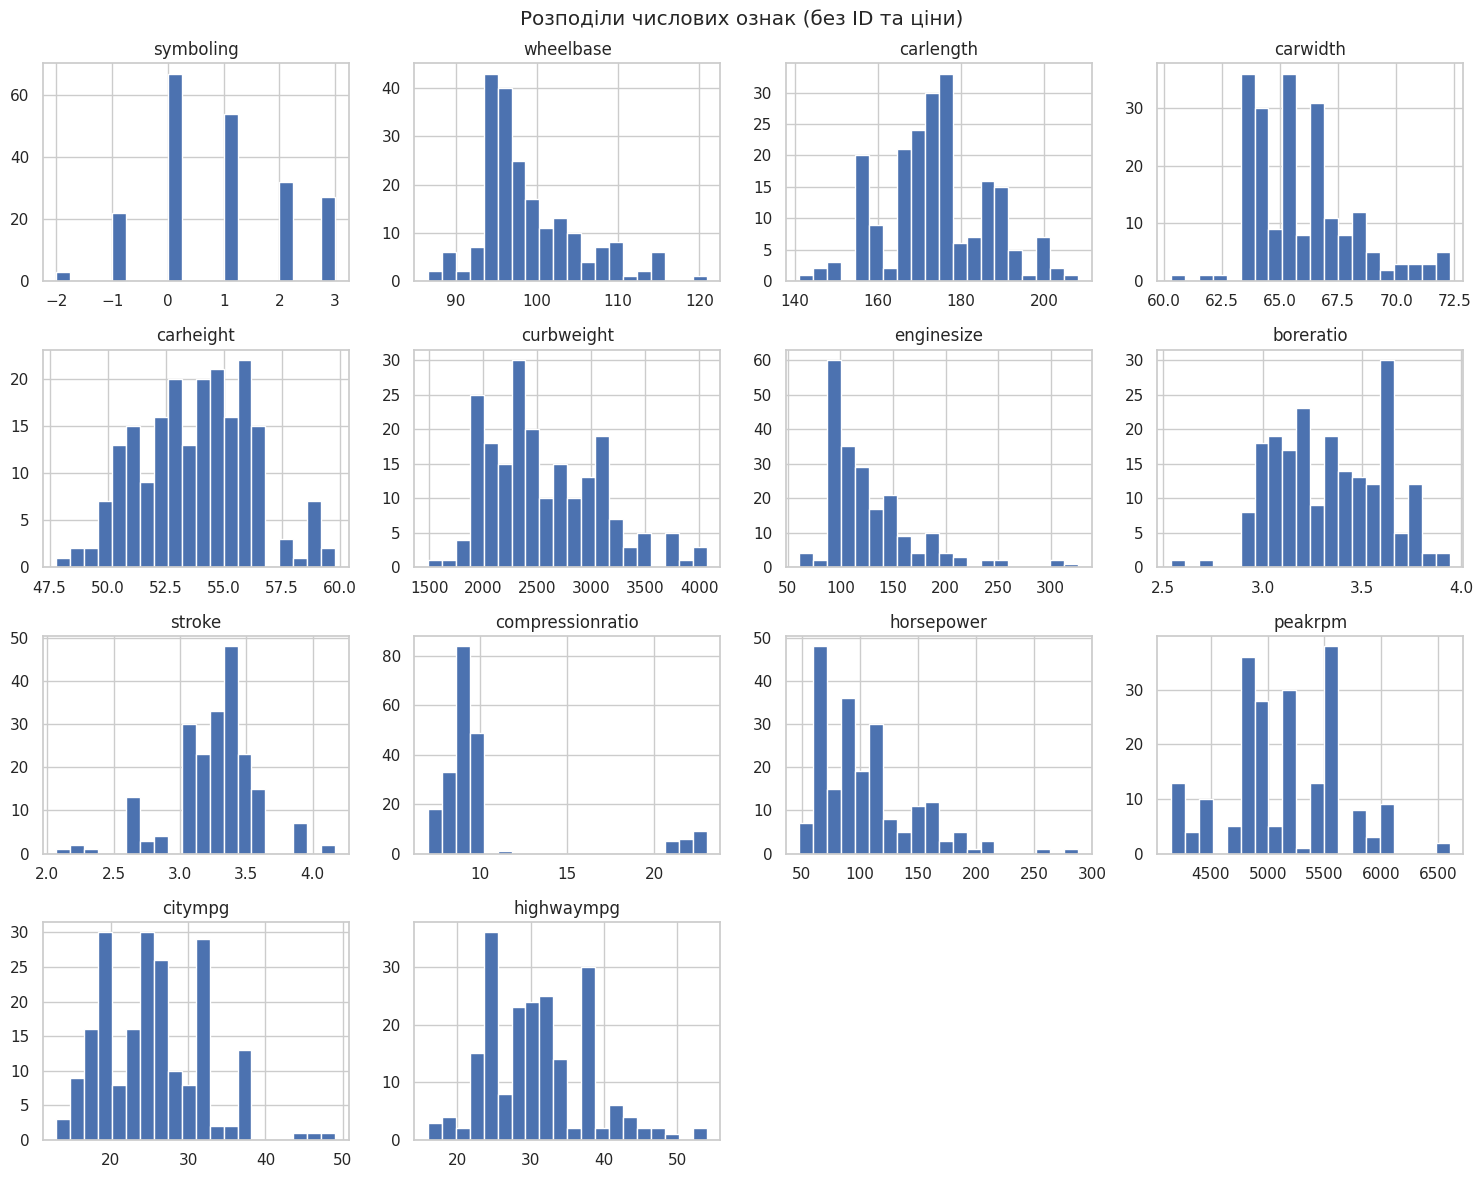

Найвиразніша асиметрія: {'compressionratio': 2.611, 'enginesize': 1.948, 'horsepower': 1.405, 'wheelbase': 1.05, 'carwidth': 0.904}
Висновок: асиметрію оцінено описово; параметри перетворення обчислимо лише за train.


In [6]:
numeric_features_all = df.select_dtypes(include=np.number).columns.drop(["car_ID", "price"], errors="ignore").tolist()
skew_initial_all = df[numeric_features_all].skew().sort_values(key=abs, ascending=False)
display(skew_initial_all.rename("Асиметрія").to_frame())
df[numeric_features_all].hist(bins=20, figsize=(15, 12))
plt.suptitle("Розподіли числових ознак (без ID та ціни)")
plt.tight_layout()
plt.show()
print("Найвиразніша асиметрія:", skew_initial_all.head(5).round(3).to_dict())
print("Висновок: асиметрію оцінено описово; параметри перетворення обчислимо лише за train.")

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [7]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["price", "car_ID"])
y = df["price"].copy()
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.20, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("ID train/test:", len(id_train), len(id_test))
print("Перетин індексів:", len(set(X_train.index) & set(X_test.index)))

Train: (164, 24) Test: (41, 24)
ID train/test: 164 41
Перетин індексів: 0


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [9]:
continuous_initial = X_train.select_dtypes(include=np.number).columns.drop("symboling", errors="ignore").tolist()
X_train_clip = X_train.copy()
X_test_clip = X_test.copy()
iqr_bounds = {}
outlier_counts = {}
for col in continuous_initial:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_bounds[col] = (low, high)
    outlier_counts[col] = int(((X_train[col] < low) | (X_train[col] > high)).sum())
    X_train_clip[col] = X_train[col].clip(lower=low, upper=high)
    X_test_clip[col] = X_test[col].clip(lower=low, upper=high)
display(pd.Series(outlier_counts, name="Кількість викидів (train)").sort_values(ascending=False).to_frame())

,Кількість викидів (train)
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


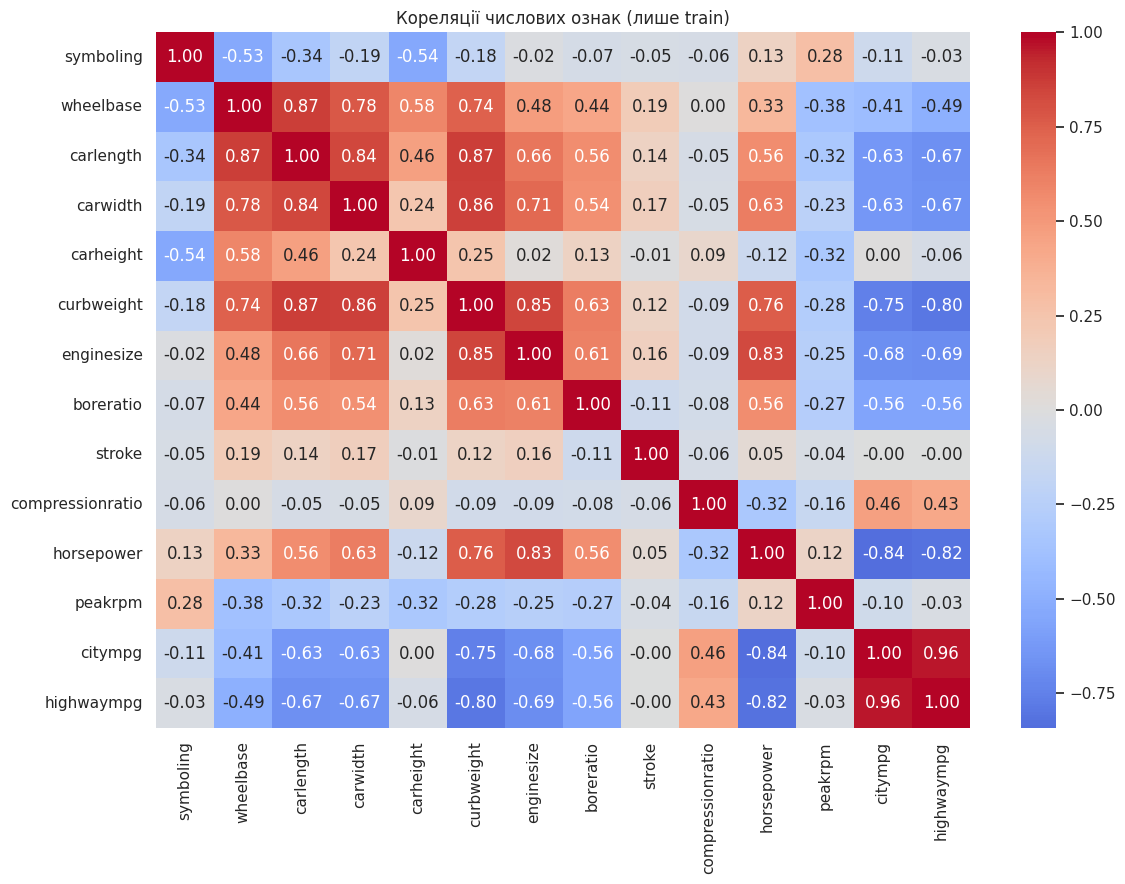

Сильно корельовані пари (|r| > 0.85):
citympg — highwaympg: r=0.964; |r з price|=0.711/0.716
wheelbase — carlength: r=0.867; |r з price|=0.504/0.652
carlength — curbweight: r=0.866; |r з price|=0.652/0.824
carwidth — curbweight: r=0.858; |r з price|=0.732/0.824
Видаляємо: ['carlength', 'carwidth', 'citympg', 'wheelbase']
Залишилось стовпців: 20


In [10]:
# Кореляції обчислюємо тільки на train після обмеження викидів.
train_num = X_train_clip.select_dtypes(include=np.number)
corr_features = train_num.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr_features, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Кореляції числових ознак (лише train)")
plt.tight_layout(); plt.show()

target_strength = train_num.apply(lambda s: abs(s.corr(y_train))).fillna(0)
pairs = []
cols = train_num.columns.tolist()
for i, a in enumerate(cols):
    for b in cols[i+1:]:
        r = corr_features.loc[a, b]
        if pd.notna(r) and abs(r) > 0.85:
            pairs.append((a, b, float(r)))
pairs.sort(key=lambda item: abs(item[2]), reverse=True)
drop_columns = set()
for a, b, r in pairs:
    if a in drop_columns or b in drop_columns:
        continue
    if target_strength[a] < target_strength[b]:
        drop_columns.add(a)
    else:
        drop_columns.add(b)
print("Сильно корельовані пари (|r| > 0.85):")
for a,b,r in pairs:
    print(f"{a} — {b}: r={r:.3f}; |r з price|={target_strength[a]:.3f}/{target_strength[b]:.3f}")
print("Видаляємо:", sorted(drop_columns))
X_train_selected = X_train_clip.drop(columns=list(drop_columns))
X_test_selected = X_test_clip.drop(columns=list(drop_columns))
print("Залишилось стовпців:", X_train_selected.shape[1])

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.base import clone

continuous_cols = X_train_selected.select_dtypes(include=np.number).columns.drop("symboling", errors="ignore").tolist()
symboling_cols = ["symboling"] if "symboling" in X_train_selected.columns else []
category_cols = X_train_selected.select_dtypes(exclude=np.number).columns.tolist()

continuous_pipe = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler())
])
cat_encoder = OneHotEncoder(handle_unknown="ignore")
preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", continuous_pipe, continuous_cols),
        ("symboling", StandardScaler(), symboling_cols),
        ("categories", cat_encoder, category_cols)
    ], remainder="drop")
print("Неперервні:", continuous_cols)
print("Дискретна:", symboling_cols)
print("Категоріальні:", category_cols)
print("Висновок: Yeo–Johnson/StandardScaler тільки для неперервних, StandardScaler для symboling, OneHotEncoder для категорій.")

Неперервні: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна: ['symboling']
Категоріальні: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']
Висновок: Yeo–Johnson/StandardScaler тільки для неперервних, StandardScaler для symboling, OneHotEncoder для категорій.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [12]:
if continuous_cols:
    transformed_cont = clone(continuous_pipe).fit_transform(X_train_selected[continuous_cols])
    before = X_train_selected[continuous_cols].skew()
    after = pd.DataFrame(transformed_cont, columns=continuous_cols).skew()
    skew_compare = pd.DataFrame({"До": before, "Після": after})
    skew_compare["Зменшилась |асиметрія|"] = skew_compare["Після"].abs() < skew_compare["До"].abs()
    display(skew_compare.sort_values("До", key=abs, ascending=False))
    print("Ознак зі зменшеною |асиметрією|:", int(skew_compare["Зменшилась |асиметрія|"].sum()), "із", len(skew_compare))
else:
    print("Неперервних ознак після відбору немає.")

,До,Після,Зменшилась |асиметрія|
enginesize,0.962394,0.044834,True
horsepower,0.850735,0.066280,True
curbweight,0.712433,0.049894,True
stroke,-0.397600,0.015846,True
highwaympg,0.243761,-0.012188,True
boreratio,0.062963,-0.005941,True
compressionratio,0.055710,0.004872,True
peakrpm,0.039773,-0.003589,True
carheight,0.028154,-0.005170,True


Ознак зі зменшеною |асиметрією|: 9 із 9


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [13]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

estimators = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=10.0, max_iter=50000),
    "Random Forest": RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR(kernel="rbf", C=1000.0, epsilon=100.0)
}
models = {name: Pipeline([("preprocess", clone(preprocessor)), ("model", est)])
          for name, est in estimators.items()}
print("Створено 6 Pipeline. Передобробка всередині кожного Pipeline навчається лише на train.")

Створено 6 Pipeline. Передобробка всередині кожного Pipeline навчається лише на train.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [14]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
rows = []
predictions = {}
for name, pipe in models.items():
    pipe.fit(X_train_selected, y_train)
    predicted_test = pipe.predict(X_test_selected)
    predicted_train = pipe.predict(X_train_selected)
    predictions[name] = predicted_test
    rows.append({
        "Модель": name,
        "R² (test)": r2_score(y_test, predicted_test),
        "MAE": mean_absolute_error(y_test, predicted_test),
        "MSE": mean_squared_error(y_test, predicted_test),
        "MAPE (%)": mean_absolute_percentage_error(y_test, predicted_test)*100,
        "R² (train)": r2_score(y_train, predicted_train)
    })
results = pd.DataFrame(rows).sort_values("R² (test)", ascending=False).reset_index(drop=True)
display(results.round(3))
best = results.iloc[0]
print(f"За R²(test) найкраща модель: {best['Модель']}; R²={best['R² (test)']:.3f}, "
      f"MAE={best['MAE']:.2f}, MSE={best['MSE']:.2f}, MAPE={best['MAPE (%)']:.2f}%")
print("Різниця train/test R² допомагає помітити можливе перенавчання.")

,Модель,R² (test),MAE,MSE,MAPE (%),R² (train)
0,Random Forest,0.951,1418.467,3.879934e+06,10.279,0.986
1,Gradient Boosting,0.930,1684.462,5.560430e+06,12.591,0.992
2,Ridge Regression,0.796,2712.776,1.612943e+07,23.065,0.962
3,Lasso Regression,0.769,2639.631,1.821969e+07,19.369,0.971
4,Linear Regression,0.548,4078.294,3.567884e+07,29.973,0.993
5,SVR,0.507,3568.125,3.893603e+07,21.096,0.562


За R²(test) найкраща модель: Random Forest; R²=0.951, MAE=1418.47, MSE=3879934.10, MAPE=10.28%
Різниця train/test R² допомагає помітити можливе перенавчання.


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


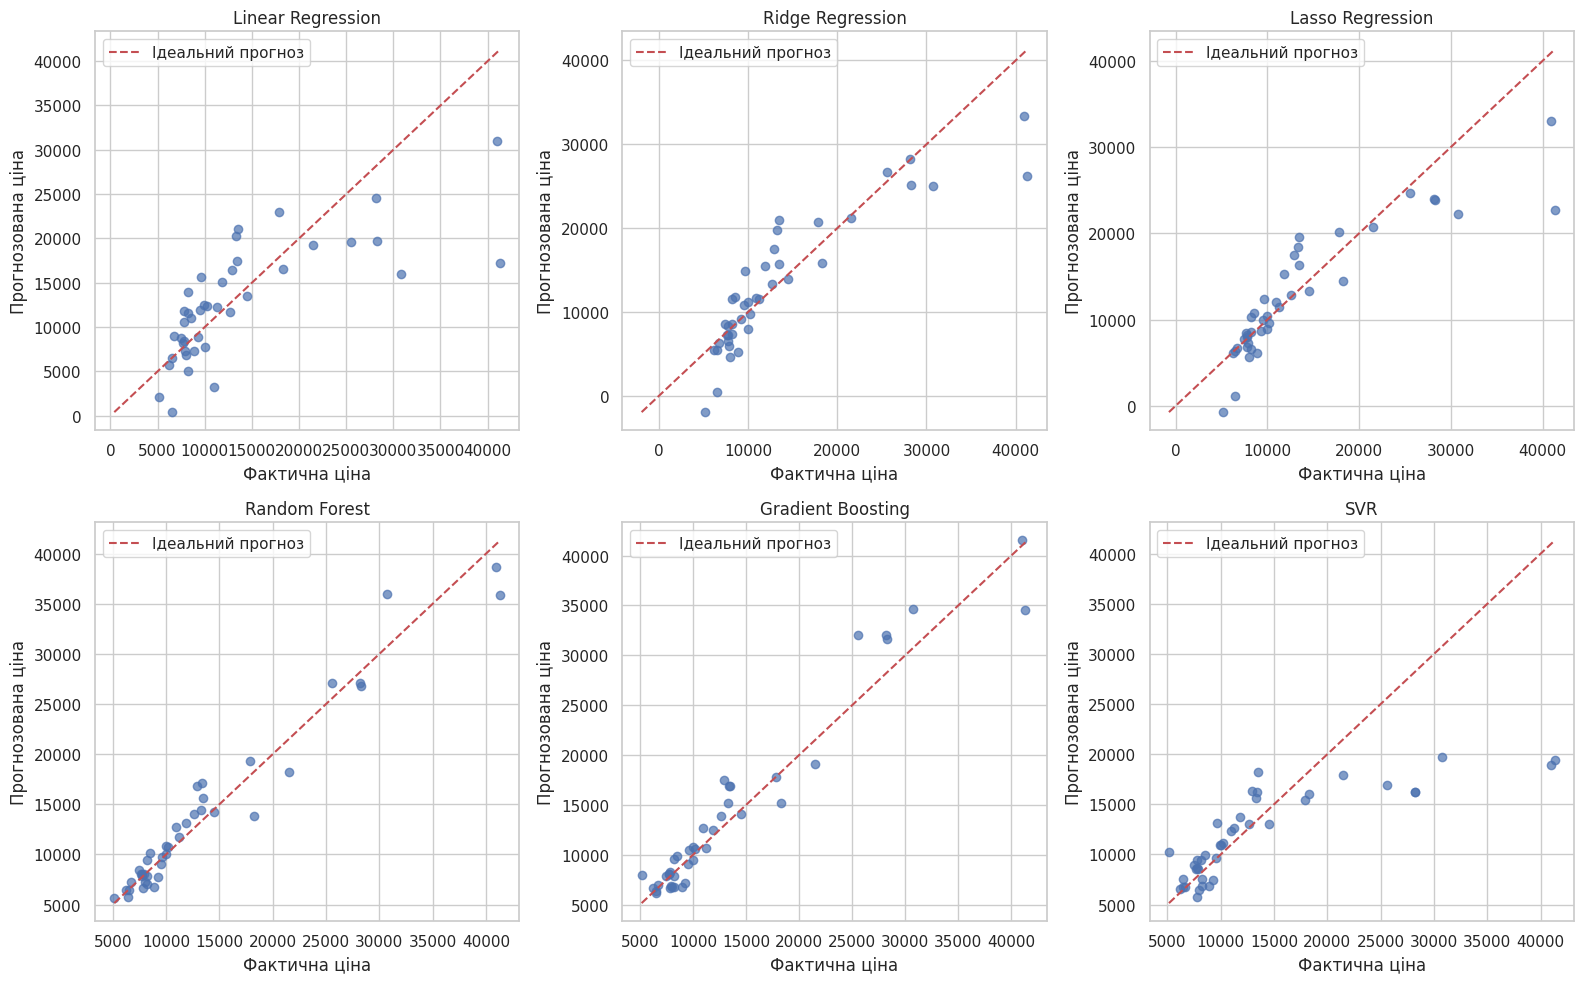

Висновок: чим ближчі точки до пунктирної діагоналі, тим точніший прогноз. Найбільші відстані — найбільші помилки.


In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, predicted) in zip(axes.flat, predictions.items()):
    ax.scatter(y_test, predicted, alpha=0.7)
    lo = min(y_test.min(), predicted.min())
    hi = max(y_test.max(), predicted.max())
    ax.plot([lo, hi], [lo, hi], "r--", label="Ідеальний прогноз")
    ax.set(title=name, xlabel="Фактична ціна", ylabel="Прогнозована ціна")
    ax.legend()
plt.tight_layout(); plt.show()
print("Висновок: чим ближчі точки до пунктирної діагоналі, тим точніший прогноз. Найбільші відстані — найбільші помилки.")

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [16]:
sample_indices = X_test_selected.sample(n=min(10, len(X_test_selected)), random_state=42).index
sample_pred = models["Random Forest"].predict(X_test_selected.loc[sample_indices])
sample_actual = y_test.loc[sample_indices].to_numpy()
ten_cars = pd.DataFrame({
    "car_ID": id_test.loc[sample_indices].to_numpy(),
    "Фактична ціна": sample_actual,
    "Прогнозована ціна": sample_pred,
    "Абсолютна помилка": np.abs(sample_actual - sample_pred),
    "Абсолютна відсоткова помилка (%)": np.where(sample_actual != 0,
      np.abs(sample_actual-sample_pred)/np.abs(sample_actual)*100, np.nan)
})
display(ten_cars.round(2))
print("Середня абсолютна помилка 10 авто:", round(ten_cars["Абсолютна помилка"].mean(),2))
print("Найбільша абсолютна помилка:", round(ten_cars["Абсолютна помилка"].max(),2))
print("Висновок: похибки різняться між автомобілями; конкретні значення наведені в таблиці.")

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7241.21,549.21,8.21
1,176,9988.0,10811.30,823.30,8.24
2,148,10198.0,10770.58,572.58,5.61
3,17,41315.0,35902.81,5412.19,13.10
4,69,28248.0,26758.41,1489.59,5.27
5,147,7463.0,8411.40,948.40,12.71
6,144,9960.0,10038.32,78.32,0.79
7,85,14489.0,14283.02,205.98,1.42
8,195,12940.0,16787.05,3847.05,29.73
9,160,7788.0,7823.38,35.38,0.45


Середня абсолютна помилка 10 авто: 1396.2
Найбільша абсолютна помилка: 5412.19
Висновок: похибки різняться між автомобілями; конкретні значення наведені в таблиці.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


In [17]:
print("ПІДСУМКОВІ ВИСНОВКИ")
print("Усі моделі оцінено на одному test-наборі. Рейтинг моделей:")
display(results[["Модель", "R² (test)", "MAE", "MSE", "MAPE (%)", "R² (train)"]].round(3))
print(f"Найкраща за R² на test: {best['Модель']} (R²={best['R² (test)']:.3f}, "
      f"MAE={best['MAE']:.2f}, MSE={best['MSE']:.2f}, MAPE={best['MAPE (%)']:.2f}%).")
for _, row in results.iterrows():
    gap = row["R² (train)"] - row["R² (test)"]
    if gap > 0.15:
        print(f"Можливі ознаки перенавчання: {row['Модель']}, різниця R²(train-test)={gap:.3f}.")
print("Обмеження за IQR, відбір корельованих ознак та кодування/масштабування "
      "виконані без використання test при обчисленні параметрів.")
print("Без окремого експерименту без передобробки не можна кількісно приписати їй приріст якості.")

ПІДСУМКОВІ ВИСНОВКИ
Усі моделі оцінено на одному test-наборі. Рейтинг моделей:


,Модель,R² (test),MAE,MSE,MAPE (%),R² (train)
0,Random Forest,0.951,1418.467,3.879934e+06,10.279,0.986
1,Gradient Boosting,0.930,1684.462,5.560430e+06,12.591,0.992
2,Ridge Regression,0.796,2712.776,1.612943e+07,23.065,0.962
3,Lasso Regression,0.769,2639.631,1.821969e+07,19.369,0.971
4,Linear Regression,0.548,4078.294,3.567884e+07,29.973,0.993
5,SVR,0.507,3568.125,3.893603e+07,21.096,0.562


Найкраща за R² на test: Random Forest (R²=0.951, MAE=1418.47, MSE=3879934.10, MAPE=10.28%).
Можливі ознаки перенавчання: Ridge Regression, різниця R²(train-test)=0.166.
Можливі ознаки перенавчання: Lasso Regression, різниця R²(train-test)=0.201.
Можливі ознаки перенавчання: Linear Regression, різниця R²(train-test)=0.445.
Обмеження за IQR, відбір корельованих ознак та кодування/масштабування виконані без використання test при обчисленні параметрів.
Без окремого експерименту без передобробки не можна кількісно приписати їй приріст якості.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
